<p align="center">
  <img src="./assets/banners/04-refresh-the-storefront.svg" alt="MAI Models · Multimodal Product Launch — Refresh the storefront: Can a coding model turn our napkin sketch into a website? Microsoft AI Samples" width="900" />
</p>

# 🛍️ Refresh the storefront

> **Can a coding model turn our napkin sketch into a website — built from our real product data, with a home for TrailMate?**

⏱️ About 10 minutes to review, or 30 minutes or more to run live · 🧱 You'll build: a new Contoso Outdoors storefront with a TrailMaster X4 launch page

**By the end, you'll be able to:**

- Turn a hand-drawn sketch into a wireframe you've checked and approved, before any code is written
- Guide a coding model in GitHub Copilot with short, checkable prompts
- Spot the coding version of *making things up*: products, prices and pages that aren't in your data

> 🧪 **This notebook is different.** The model works in **GitHub Copilot**, not in a notebook cell. Each step is a **prompt** you paste into Copilot Chat. The cells here only check your tools and show what each step produced: your files if you ran it, or our results if you're reading.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.1 The story: a napkin and a chatbot

Contoso's website hasn't changed since 2023. The web team sketched a new one on a napkin (you saw it in 0.4): four screens, a chat bubble on every page, and three ways in.

The chat bubble is box ④, **ASK CONTOSO**. That's where TrailMate, Contoso's support agent, will answer customers once it's built.

Today we hand the napkin to a coding model, and steer it one small step at a time:

1. Read the napkin, and say what it couldn't read
2. Fix those gaps, and approve a wireframe
3. Build the catalog from **our** product data
4. Add the TrailMaster X4 launch page, with the assets from 01 to 03
5. Give TrailMate a home
6. Preview it

### Pick your route

| Route | Sections | Good for |
| --- | --- | --- |
| ⚡ **Short** (about 5 minutes to review) | 4.5, 4.6, 4.7, 4.10 | Seeing the sketch-to-site idea |
| 🧭 **Full** (about 10 minutes to review) | All of them | Running it yourself, with no time pressure |

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.2 New words

| Word | In plain words |
| --- | --- |
| **Wireframe** | A simple drawing of each screen: boxes and labels, no colors or code |
| **Static site** | A website made of plain files, with no server code. Fast and cheap to host |
| **Astro** | A tool that builds a static site, and can read Markdown files, like our product manuals |
| **Agent mode** | A Copilot Chat mode where the model can create files and run commands, after you approve them |
| **Model picker** | The menu in Copilot Chat where you choose which model answers |

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.3 Before you start

**Just reading?** Skip to 4.5: every step shows our screenshots.

**Running it live?** You need:

| You need | How to check |
| --- | --- |
| VS Code with **GitHub Copilot** signed in | The Copilot icon in the status bar |
| A **MAI-Code Flash** model | In Copilot Chat, open the **model picker** and choose the latest **MAI-Code-X.Y-Flash**. It may be marked **preview**. If you don't see one, your Copilot plan may not include it yet; any model works for the steps, but your results will differ |
| **Agent mode** | Switch the chat mode from *Ask* to *Agent* |
| **Node.js** and npm | The dev container has them. The next cell checks |

**Start a new chat** for this notebook, so earlier conversations don't steer the model. Read each change Copilot proposes before you accept it.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.4 Get set up

This cell doesn't call any model. It checks your tools and makes the folder Copilot will build in. It also defines `shots()`, which shows each step's result.

> 🔮 **Guess first:** which Node.js version does the dev container have?

In [1]:
import shutil
import subprocess
from pathlib import Path

from IPython.display import SVG, Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "contoso-retail").is_dir())
HERE = ROOT / "workshops" / "mai-multimodal-product-launch"
DATA = ROOT / "data" / "contoso-retail"  # The shared product catalog the site is built from
WORK = HERE / "output" / "04"          # Where Copilot builds the site. Git ignores this folder.
EXAMPLES = HERE / "examples" / "04"    # The wireframes and storefront from our run
WORK.mkdir(parents=True, exist_ok=True)


def version(tool: str) -> str:
    path = shutil.which(tool)
    return subprocess.run([path, "--version"], capture_output=True, text=True).stdout.strip() if path else "not found"


def shots(step: str) -> None:
    """Show what this step produced: your files first, then ours."""
    mine = sorted(WORK.glob(f"{step}-*.svg"))
    ours = sorted(EXAMPLES.glob(f"{step}-*"))
    for path in mine or ours:
        print(f"{'🖼️ yours' if path.parent == WORK else '🔁 ours'} · {path.name}")
        display(SVG(filename=str(path)) if path.suffix == ".svg" else Image(filename=str(path), width=720))
    if not (mine or ours):
        print(f"📸 No result saved for step {step} yet. Run the prompt in Copilot, then look at the files it made.")


print(f"Node.js: {version('node')} · npm: {version('npm')}")
print(f"Napkin sketches: {', '.join(p.name for p in sorted((HERE / 'assets' / 'napkin').glob('*.webp')))}")
print(f"Product data: {len(list((DATA / 'manuals').glob('*.md')))} manuals in {DATA.relative_to(ROOT)}/")
print(f"Copilot builds in: {WORK.relative_to(ROOT)}/")

Node.js: v26.13.0 · npm: 11.20.0
Napkin sketches: crumpled.webp, inked.webp, napkin-draft.webp
Product data: 20 manuals in data/contoso-retail/
Copilot builds in: workshops/mai-multimodal-product-launch/output/04/


<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.5 Read the napkin

<img src="./assets/asks/04-05.svg" alt="Your customer asks: Here's our napkin sketch. Can you read it before you build it?" width="900" />
<br/>

Here's the sketch, inked on a real napkin. Before writing any code, we ask the model to read it, and to **tell us what it couldn't read** instead of guessing.

<img src="./assets/napkin/inked.webp" alt="A hand-drawn napkin sketch of the new Contoso Outdoors store." width="380" />

**📋 Prompt 1.** Paste this into the Copilot chat, with **workshops/mai-multimodal-product-launch/assets/napkin/inked.webp** attached:

```text
Look at the attached napkin sketch of a new website for Contoso Outdoors.

1. Create workshops/mai-multimodal-product-launch/output/04/1-wireframe.svg: a clean wireframe of exactly what is drawn, in the style of workshops/mai-multimodal-product-launch/assets/napkin/napkin-draft.webp. Use simple boxes, the screen numbers and short labels.
2. Then list every word or element you couldn't read with confidence. Mark each one "unclear". Don't guess.
3. Don't add any page or feature that isn't on the napkin.
```

> 🔮 **Guess first:** which parts will it mark as unclear?

🔁 ours · 1-wireframe.svg


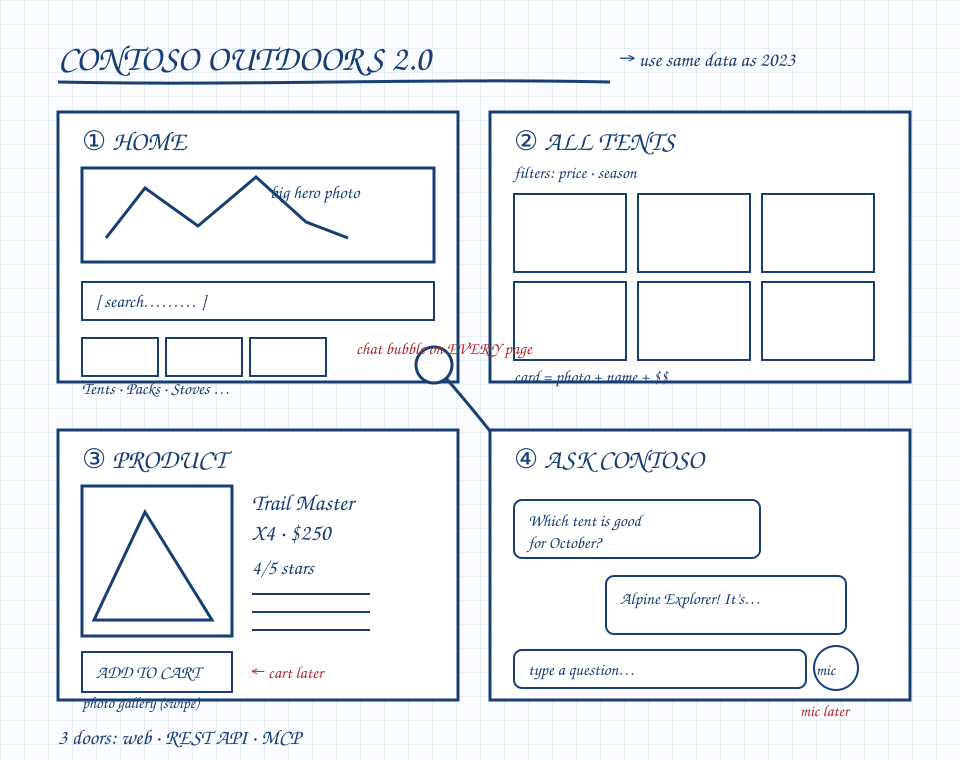

In [2]:
shots("1")  # the wireframe from the napkin

👀 **What to look for:**

- [ ] Four screens, numbered like the napkin: Home, All tents, Product, Ask Contoso.
- [ ] The three "doors": web, REST API and MCP.
- [ ] An **unclear** list. Did it flag the tiny *filters* note, the ink blot, or the note in the corner?
- [ ] **No extras**: no cart, login or checkout. They're not on the napkin.

⚠️ **The honest limit:** a model that guesses quietly is worse than one that says *"I couldn't read this"*. It's *making things up*, applied to a sketch.

🧪 **Try it yourself:** run the same prompt with `crumpled.webp`. Does the unclear list get longer?

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.6 Fix it, then approve it

<img src="./assets/asks/04-06.svg" alt="Your customer asks: It got a few things wrong. How do we fix them before building?" width="900" />
<br/>

You're the one who knows what the team meant. Answer each unclear item, then approve the wireframe. **Every later step uses only this approved version.**

**📋 Prompt 2.** Paste this into the Copilot chat:

```text
Here are my answers to the unclear items: <write your answers here>.

Update the wireframe and save it as workshops/mai-multimodal-product-launch/output/04/2-wireframe-approved.svg.
Then create workshops/mai-multimodal-product-launch/output/04/wireframe-notes.md that lists, for each screen: what's on it, and what's "not now" (anything the napkin marks as later, like the microphone).
```

> 🔮 **Guess first:** how many of your answers will change the wireframe?

🔁 ours · 2-wireframe-approved.svg


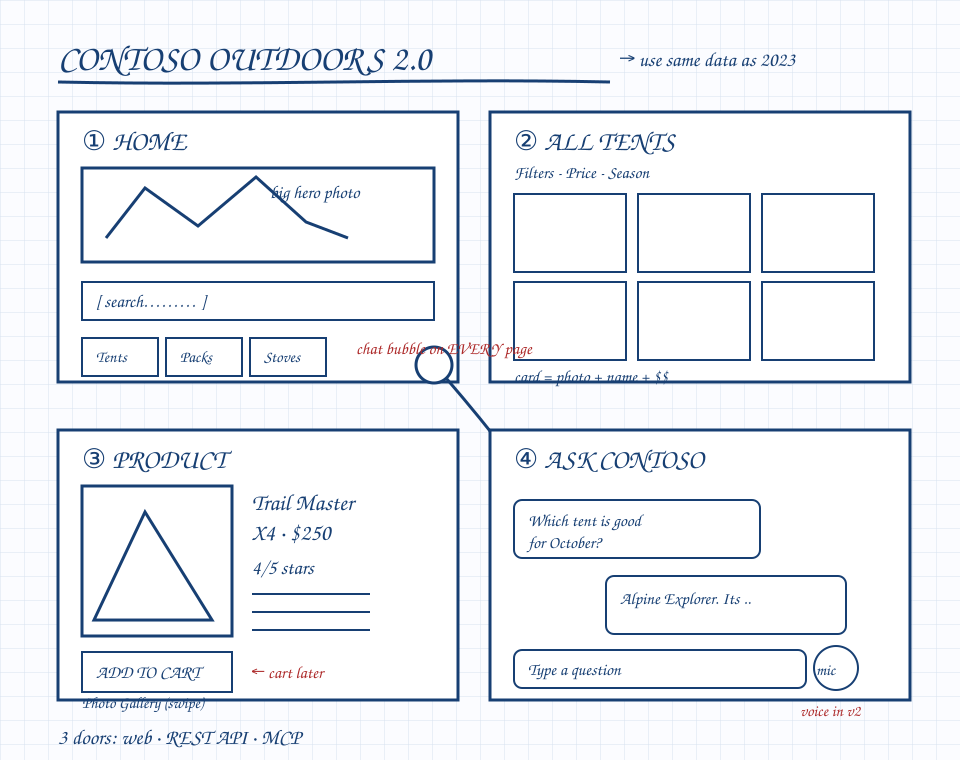

In [3]:
shots("2")  # the approved wireframe

👀 **What to look for:**

- [ ] Every unclear item is resolved, the way **you** said.
- [ ] *Not now* lists the microphone ("MIC LATER v2").
- [ ] Nothing new crept in while it was fixing things.

✅ **Approve it:** if it's right, you're done with planning. If not, say exactly what's wrong and ask again. Don't move on with a wireframe you wouldn't sign off.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.7 Build the catalog from our data

<img src="./assets/asks/04-07.svg" alt="Your customer asks: Build the catalog from our real data, not from made-up products." width="900" />
<br/>

Now the code. The site must use **our** products, from the shared [Contoso Retail dataset](../../data/contoso-retail/README.md), not products the model imagines.

**📋 Prompt 3.** Paste this into the Copilot chat:

```text
Using only workshops/mai-multimodal-product-launch/output/04/2-wireframe-approved.svg and wireframe-notes.md, create a static site with Astro in workshops/mai-multimodal-product-launch/output/04/storefront.

Build the catalog from the real product data in data/contoso-retail/:
- products.json (name, price, brand, category, description, manual and image paths for every product)
- the Markdown manuals in manuals/ (features and specs)
- the product photos in images/<slug>/ (WebP; 01.webp is the main photo)

Include Home, All tents (with filters for price and season), and a Product page for every product.
Don't invent products, prices or features. Use plain CSS.

Then run npm install and npm run build, and fix any errors.
```

> 🔮 **Guess first:** how many product pages will it build?

In [4]:
shots("3")  # the catalog pages

📸 No result saved for step 3 yet. Run the prompt in Copilot, then look at the files it made.


👀 **What to look for:**

- [ ] One product page per product in `products.json` (20), no more and no fewer.
- [ ] Prices match the data. The TrailMaster X4 is **$250**.
- [ ] The X4 page says what the manual says, and doesn't promote *water-resistant* to *waterproof*.
- [ ] The build finishes without errors.

⚠️ **The honest limit:** a coding model will happily write good-looking code around a made-up product. Check the **data**, not just the page. Pick three products and compare them with their manuals.

> 📝 **About our saved run:** the storefront in `examples/04/storefront` was built from an earlier, ten-product version of this data. Your run uses all twenty.

🧪 **Try it yourself:** ask it to add the brand to each product card. Did it read the brand from the data, or guess?

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.8 Add the launch page

<img src="./assets/asks/04-08.svg" alt="Your customer asks: The launch kit is ready. Can the new page use it?" width="900" />
<br/>

The launch kit from notebooks 01 to 03 gets its own page.

**📋 Prompt 4.** Paste this into the Copilot chat:

```text
Add a launch page for the TrailMaster X4 at /launch in workshops/mai-multimodal-product-launch/output/04/storefront.

Use the new assets from workshops/mai-multimodal-product-launch/, taking each from output/ first, then examples/:
- pictures from output/01 or examples/01 (the launch poster, the four seasons, the setup guide)
- the English radio spot from output/02 or examples/02, with a play button
- the transcript of that spot from output/03 or examples/03, shown as captions

Convert any PNG to WebP. Describe the tent as water-resistant, with a rainfly; don't call it waterproof. Label the pictures and the voice as AI-generated.

Also add a Launch item to the nav bar, and update the Home page hero banner to mention the launch.
```

> 🔮 **Guess first:** will it find the files in `examples/` if you haven't run 01 to 03 live?

In [5]:
shots("4")  # the launch page

📸 No result saved for step 4 yet. Run the prompt in Copilot, then look at the files it made.



**📋 Prompt 4b.** Paste this into the Copilot chat:

```text
Improve the color scheme and palette for the site to give this a clean modern look reflecting a fall color palette. Use appropriate fonts and add a theme toggle. Make sure palette works for both modes
```


👀 **What to look for:**

- [ ] The poster, the seasons and the setup guide all show up.
- [ ] The radio spot plays, and its captions match what you hear.
- [ ] It says **water-resistant**, and labels the AI-made content.

⚠️ **The honest limit:** asset paths are where generated sites break first. If a picture is missing, ask Copilot to list the files it expected, then compare them with what's on disk.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.9 Give TrailMate a home

<img src="./assets/asks/04-09.svg" alt="Your customer asks: Our chatbot needs a home. Where does TrailMate fit on the site?" width="900" />
<br/>

Box ④ on the napkin: a chat bubble on every page. TrailMate, the support agent, isn't built yet. Here, we only build its home, and keep the connection easy to add later.

**📋 Prompt 5.** Paste this into the Copilot chat:

```text
Add the "Ask Contoso" chat panel from the wireframe to every page.

Don't connect it to a model yet. Show a short message saying TrailMate, our support agent, will answer here.
Put the call to the chat service in one small function, askTrailMate(question), that returns a placeholder for now, so we can connect it to the TrailMate agent later.
```

> 🔮 **Guess first:** will it try to connect to a real model anyway?

In [6]:
shots("5")  # the Ask Contoso panel

📸 No result saved for step 5 yet. Run the prompt in Copilot, then look at the files it made.


👀 **What to look for:**

- [ ] The panel is on every page, as the napkin shows.
- [ ] `askTrailMate()` is one small function, easy to find.
- [ ] No keys, endpoints or secrets were added to the site.

⚠️ **The honest limit:** a static site can't keep a secret. When you connect TrailMate, the call must go through a small server you control, never straight from the browser with a key.

🧪 **Go further:** build TrailMate as an agent in Microsoft Foundry, grounded in the manuals in `data/contoso-retail/manuals/`, and connect `askTrailMate()` to it through a small API.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.10 Preview it

<img src="./assets/asks/04-10.svg" alt="Your customer asks: Is it good enough to show the team? Let's preview it." width="900" />
<br/>

Time to see it running.

**📋 Prompt 6.** Paste this into the Copilot chat:

```text
Start the site in development mode from workshops/mai-multimodal-product-launch/output/04/storefront and tell me the local address.
Then check every page for broken links and missing images, and list anything you find.
```

Open the address in the browser. Take a screenshot of the home page and the launch page.

> 🔮 **Guess first:** what's the first thing a customer would click?

In [7]:
shots("6")  # the finished storefront

📸 No result saved for step 6 yet. Run the prompt in Copilot, then look at the files it made.


👀 **What to look for:**

- [ ] Every page from the wireframe works, and nothing extra appeared.
- [ ] No broken links or missing pictures.
- [ ] The X4 launch page tells the same story as the posters and the radio spot.

⚠️ **The honest limit:** a site that builds and looks right can still be wrong. The checklists in 4.7 and 4.8 matter more than how polished it looks.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.11 Which coding model do you need?

Copilot offers several models. For this notebook we use a **MAI-Code Flash** model: a fast model for coding agents. A Flash model suits short, well-scoped prompts like ours.

We haven't compared models here, so we won't claim a winner. To compare on your own work:

1. Run Prompt 3 with one model, and score it with the checklist in 4.7.
2. Start a new chat, pick a different model, and run the same prompt.
3. Compare the checklist scores, the time it took, and how many fixes you had to ask for.

That's a fair comparison for any model choice: **same task, same checklist, one change at a time.**

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.12 Teach it to a customer

### What it did, and where to show it

| Step | Why a customer cares | Show them |
| --- | --- | --- |
| Read a sketch, and say what's unclear | Fewer wrong guesses baked into code | 4.5 |
| A wireframe a person approves | Control before anything is built | 4.6 |
| A catalog from real data | No made-up products or prices | 4.7 |
| A launch page from new assets | Pictures, voice and captions in one place | 4.8 |
| A home for the chatbot | A support agent on the website, ready to connect | 4.9 |

### A prompt recipe that works

1. **One step per prompt.** Read, then approve, then build.
2. **Name the source of truth**: the approved wireframe, the product data.
3. **Say what not to do**: no extra pages, no invented products.
4. **Ask it to check its work**: build, then list problems.

### Honest answers to common questions

| They ask… | You can say… |
| --- | --- |
| Is the MAI-Code model ready for production? | Check its status in the model picker; it may be in **preview**. Review every change before you accept it. |
| Will it make things up? | It can. Name your data source, and check the result against it. |
| Can it connect our chatbot? | Yes, through a small server you control. Never put a key in the browser. |

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.13 Check yourself

1. Why did we approve a wireframe before writing any code?
2. The catalog shows twenty-one products. What do you do?
3. Where should the call to TrailMate run: in the browser, or on a server?

<details>
<summary>Show answers</summary>

1. Fixing a sketch is cheap; fixing code built on a wrong guess isn't. And every later prompt can point at one approved source.
2. Find the extra one, compare it with `data/contoso-retail/products.json`, and ask Copilot to remove anything not in the data.
3. On a server. A static site can't keep a key secret.

</details>

### 🤖 Ask your agent

- *"Review workshops/mai-multimodal-product-launch/output/04/storefront and list anything that isn't backed by data/contoso-retail/."*
- *"Write a test that checks every product page's price against data/contoso-retail/products.json."*

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 4.14 Cost and cleanup

This notebook doesn't create any Azure resources. Copilot usage follows your GitHub Copilot plan. When you're done:

- **Keep `output/04/storefront`** if you want to keep building; Git ignores the folder.
- **Delete `output/04/`** to start fresh.
- **Finished the workshop?** Run `bash infra/teardown.sh` to delete the Azure resources from notebooks 01 to 03.

🎉 **That's the launch kit:** pictures, voice, transcripts and a storefront, each from the model that fits the job.

➡️ **Next:** back to the [workshop README](./README.md).